In [3]:
!pip install -U transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 21.8 MB/s  0:00:00m0:00:010:01
  Attempting uninstall: transformers
    Found existing installation: transformers 5.20.2
    Uninstalling transformers-5.20.2:
      Successfully uninstalled transformers-5.20.2


## Local Inference on GPU 
Model page: https://huggingface.co/ProsusAI/finbert

⚠️ If the generated code snippets do not work, please open an issue on either the [model repo](https://huggingface.co/ProsusAI/finbert)
			and/or on [huggingface.js](https://github.com/huggingface/huggingface.js/blob/main/packages/tasks/src/model-libraries-snippets.ts) 🙏

In [4]:
# Use a pipeline as a high-level helper
from transformers import pipeline

pipe = pipeline("text-classification", model="ProsusAI/finbert")

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [5]:
# pip install -U transformers accelerate
# Load model directly
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert", device_map="auto")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [6]:
text = "The company reported strong revenue growth."

result = pipe(text, top_k=None)
print(result)

[{'label': 'positive', 'score': 0.9531024098396301}, {'label': 'neutral', 'score': 0.03277944400906563}, {'label': 'negative', 'score': 0.014118149876594543}]


In [7]:
import torch

text = "The company reported strong revenue growth."

inputs = tokenizer(text, return_tensors="pt")

device = next(model.parameters()).device
inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

logits = outputs.logits
probabilities = torch.softmax(logits, dim=-1)

print("Logits:", logits)
print("Probabilities:", probabilities)

Logits: tensor([[ 2.1083, -2.1040, -1.2617]], device='cuda:0')
Probabilities: tensor([[0.9531, 0.0141, 0.0328]], device='cuda:0')


## Testing news text

In [8]:
test_texts = [
    "The company reported record revenue and strong earnings.",
    "The firm announced significant layoffs after disappointing results.",
    "The company maintained its earnings guidance.",
    "Shares declined following weaker-than-expected quarterly results.",
    "The company reported revenue in line with analyst expectations.",
    "Nothing new to the company.",
    "Massive downfall to the Tesla after the war striking USA.",
    "Merck, Pfizer, Abbott, J&J, Sanofi Said to Show Interest in Bausch & Lomb Bid - Bloomberg.",
    "UPDATE: Citigroup Reiterates Neutral Rating, Raises PT on American Tower Corp."
]

results = pipe(test_texts, top_k=None)

for text, result in zip(test_texts, results):
    print("\nText:", text)
    print(result)


Text: The company reported record revenue and strong earnings.
[{'label': 'positive', 'score': 0.9470416307449341}, {'label': 'neutral', 'score': 0.039386894553899765}, {'label': 'negative', 'score': 0.013571476563811302}]

Text: The firm announced significant layoffs after disappointing results.
[{'label': 'negative', 'score': 0.9727678298950195}, {'label': 'neutral', 'score': 0.0194539912045002}, {'label': 'positive', 'score': 0.007778194732964039}]

Text: The company maintained its earnings guidance.
[{'label': 'positive', 'score': 0.6881186962127686}, {'label': 'neutral', 'score': 0.2923906147480011}, {'label': 'negative', 'score': 0.019490676000714302}]

Text: Shares declined following weaker-than-expected quarterly results.
[{'label': 'negative', 'score': 0.9695258140563965}, {'label': 'neutral', 'score': 0.02303312160074711}, {'label': 'positive', 'score': 0.007441041059792042}]

Text: The company reported revenue in line with analyst expectations.
[{'label': 'positive', 'score

## Remote Inference via Inference Providers 
Ensure you have a valid **HF_TOKEN** set in your environment. You can get your token from [your settings page](https://huggingface.co/settings/tokens). Note: running this may incur charges above the free tier.
The following Python example shows how to run the model remotely on HF Inference Providers, automatically selecting an available inference provider for you. 
For more information on how to use the Inference Providers, please refer to our [documentation and guides](https://huggingface.co/docs/inference-providers/en/index).

In [9]:
# import os
# os.environ['HF_TOKEN'] = 'YOUR_TOKEN_HERE'

In [10]:
# import os
# from huggingface_hub import InferenceClient

# client = InferenceClient(
#     provider="auto",
#     api_key=os.environ["HF_TOKEN"],
# )

# result = client.text_classification(
#     "I like you. I love you",
#     model="ProsusAI/finbert",
# )

In [11]:
import pandas as pd

file_path = '/kaggle/input/datasets/qkhilithi3122411100/top10-official-news-2013-2023/top10_official_news_2013_2023.csv'
# Sử dụng low_memory=False để bỏ cảnh báo DtypeWarning trước đó
df = pd.read_csv(file_path, low_memory=False)

print("Các cột hiện có:", df.columns.tolist())
df.head(2)

Các cột hiện có: ['Standard_Ticker', 'Date', 'Article_title', 'Stock_symbol', 'Url', 'Publisher', 'Author', 'Article', 'Lsa_summary', 'Luhn_summary', 'Textrank_summary', 'Lexrank_summary', 'Unnamed: 0']


,Standard_Ticker,Date,Article_title,Stock_symbol,Url,Publisher,Author,Article,Lsa_summary,Luhn_summary,Textrank_summary,Lexrank_summary,Unnamed: 0
0,AMT,2013-01-02 00:00:00 UTC,"UPDATE: Citigroup Reiterates Neutral Rating, R...",AMT,https://www.benzinga.com/analyst-ratings/analy...,Dwight Einhorn,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AMT,2013-01-02 00:00:00 UTC,Citigroup Maintains Neutral on American Tower ...,AMT,https://www.benzinga.com/news/13/01/3209128/ci...,Juan Lopez,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
import torch
from transformers import pipeline
from tqdm.auto import tqdm

# 1. Xác định thiết bị tính toán: GPU nếu có, ngược lại dùng CPU
device = 0 if torch.cuda.is_available() else -1
print(f"Đang chạy trên thiết bị: {'GPU' if device == 0 else 'CPU'}")

# 2. Khởi tạo pipeline sentiment-analysis với FinBERT
sentiment_pipe = pipeline(
    "sentiment-analysis",
    model="ProsusAI/finbert",
    tokenizer="ProsusAI/finbert",
    device=device,
    truncation=True,
    max_length=128 # Tiêu đề ngắn nên 128 token là tối ưu tốc độ
)

# 3. Thay 'headline' bằng tên cột tiêu đề thực tế trong DataFrame của bạn
text_col = 'Article_title' if 'Article_title' in df.columns else df.columns[8]

# Loại bỏ các dòng trống/NaN và ép kiểu chuỗi
texts = df[text_col].fillna("").astype(str).tolist()

# 4. Dự đoán theo batch
batch_size = 64
results = []

for out in tqdm(sentiment_pipe(texts, batch_size=batch_size), total=len(texts), desc="Đang phân tích cảm xúc"):
    results.append(out)

# 5. Lưu kết quả nhãn và điểm tin cậy vào DataFrame
df['sentiment_label'] = [res['label'] for res in results]
df['sentiment_score'] = [res['score'] for res in results]

# Lưu file kết quả ra thư mục làm việc của Kaggle
df.to_csv('/kaggle/working/news_with_sentiment.csv', index=False)
print("Đã hoàn tất và lưu file tại /kaggle/working/news_with_sentiment.csv")

Đang chạy trên thiết bị: GPU


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Đang phân tích cảm xúc:   0%|          | 0/92721 [00:00<?, ?it/s]

Đã hoàn tất và lưu file tại /kaggle/working/news_with_sentiment.csv


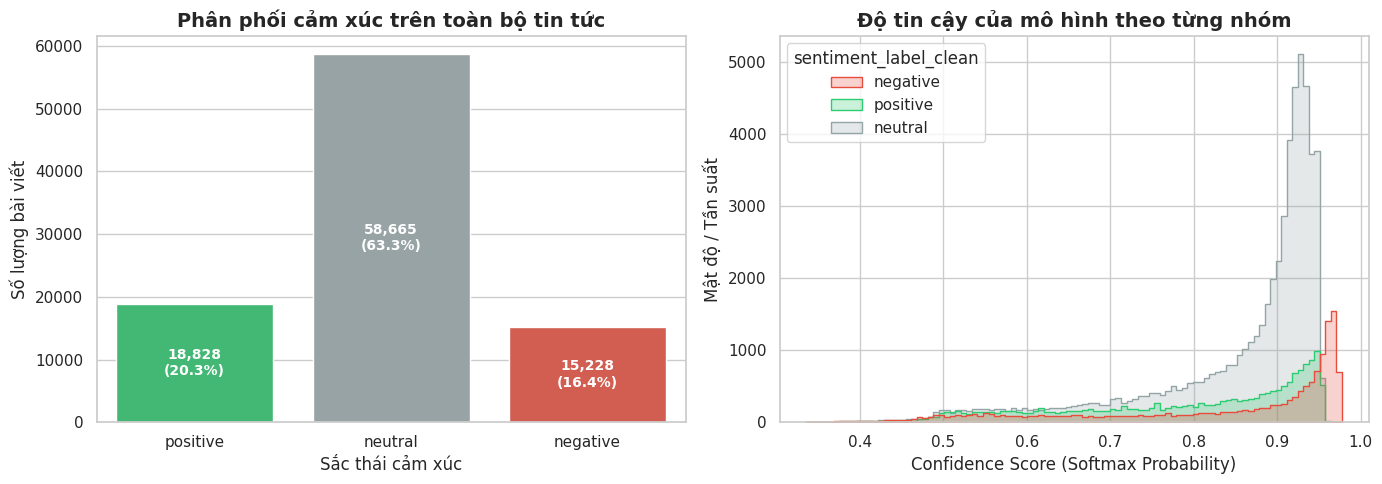

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Chuẩn hóa nhãn về chữ thường để đồng nhất
df['sentiment_label_clean'] = df['sentiment_label'].astype(str).str.lower()

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

color_palette = {"positive": "#2ecc71", "negative": "#e74c3c", "neutral": "#95a5a6"}
order = ['positive', 'neutral', 'negative']

# 1. Biểu đồ cột: Dùng hue và legend=False để sửa FutureWarning
sns.countplot(
    data=df, 
    x='sentiment_label_clean', 
    hue='sentiment_label_clean',
    order=order,
    palette=color_palette, 
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Phân phối cảm xúc trên toàn bộ tin tức', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Sắc thái cảm xúc', fontsize=12)
axes[0].set_ylabel('Số lượng bài viết', fontsize=12)

total = len(df)
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        pct = (height / total) * 100
        axes[0].annotate(f'{int(height):,}\n({pct:.1f}%)',
                         (p.get_x() + p.get_width() / 2., height / 2),
                         ha='center', va='center', color='white', fontweight='bold', fontsize=10)

# 2. Biểu đồ phân bố điểm số tin cậy
sns.histplot(
    data=df, 
    x='sentiment_score', 
    hue='sentiment_label_clean', 
    palette=color_palette, 
    element='step', 
    common_norm=False, 
    ax=axes[1]
)
axes[1].set_title('Độ tin cậy của mô hình theo từng nhóm', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Confidence Score (Softmax Probability)', fontsize=12)
axes[1].set_ylabel('Mật độ / Tần suất', fontsize=12)

plt.tight_layout()
plt.show()

In [14]:
# Giả sử cột ngày tên là 'date'
if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df['year'] = df['date'].dt.year
    
    # Tính số lượng theo từng năm và sắc thái
    yearly_sentiment = df.groupby(['year', 'sentiment_label']).size().unstack(fill_value=0)
    
    yearly_sentiment[['positive', 'neutral', 'negative']].plot(
        kind='bar', 
        stacked=True, 
        figsize=(12, 6), 
        color=['#2ecc71', '#95a5a6', '#e74c3c']
    )
    plt.title('Biến động số lượng cảm xúc tin tức theo từng năm (2013 - 2023)', fontsize=14, fontweight='bold')
    plt.xlabel('Năm', fontsize=12)
    plt.ylabel('Số lượng tin', fontsize=12)
    plt.legend(title='Cảm xúc')
    plt.show()

In [15]:
import pandas as pd
import numpy as np

file_path = '/kaggle/input/datasets/qkhilithi3122411100/top10-official-news-2013-2023/top10_official_news_2013_2023.csv'

# Đọc file với low_memory=False
df = pd.read_csv(file_path, low_memory=False)

print(f"=== TỔNG QUAN DỮ LIỆU ===")
print(f"Tổng số dòng: {len(df):,}")
print(f"Tổng số cột: {len(df.columns)}")
print(f"Danh sách cột: {list(df.columns)}\n")

# 1. BẢNG KIỂM TRA ĐỊNH DẠNG VÀ TỶ LỆ DỮ LIỆU TỪNG CỘT
report = []
for idx, col in enumerate(df.columns):
    # Đếm số kiểu dữ liệu khác nhau xuất hiện trong cột (bỏ qua NaN)
    valid_values = df[col].dropna()
    type_counts = valid_values.apply(lambda x: type(x).__name__).value_counts().to_dict()
    
    missing_count = df[col].isna().sum()
    missing_pct = (missing_count / len(df)) * 100
    
    # Kiểm tra xem có chứa ký tự xuống dòng khiến văn bản bị vỡ layout không
    has_newlines = valid_values.astype(str).str.contains(r'[\r\n]').any()
    
    report.append({
        'Index': idx,
        'Tên Cột': col,
        'Dữ Liệu Trống (NaN)': f"{missing_count:,} ({missing_pct:.1f}%)",
        'Số Kiểu Dữ Liệu': len(type_counts),
        'Chi Tiết Kiểu Dữ Liệu': str(type_counts),
        'Chứa Ký Tự Xuống Dòng': 'CÓ' if has_newlines else 'Không'
    })

report_df = pd.DataFrame(report)
print("=== CHI TIẾT ĐỊNH DẠNG TỪNG CỘT ===")
display(report_df)

# 2. KIỂM TRA CÁC DÒNG BỊ LỆCH CỘT (MISALIGNED ROWS)
# Trong các dòng chuẩn, cột đầu tiên thường là mã chứng khoán (như FDX) và cột thứ 2 là ngày (YYYY-MM-DD)
print("\n=== KIỂM TRA DÒNG BỊ ĐÈ / TRÔI DÒNG ===")
first_col = df.columns[0]
second_col = df.columns[1]

# Dòng bị lệch thường có cột 2 rỗng hoặc cột 1 chứa một đoạn văn bản dài thay vì ticker ngắn
suspicious_rows = df[
    (df[first_col].astype(str).str.len() > 10) | # Ticker bình thường chỉ 3-5 ký tự
    (df[second_col].isna()) |
    (df[second_col].astype(str).str.contains(r'^[a-zA-Z]', na=False)) # Cột ngày nhưng bắt đầu bằng chữ cái
]

print(f"Số dòng nghi vấn bị lệch cấu trúc: {len(suspicious_rows):,} / {len(df):,}")

if len(suspicious_rows) > 0:
    print("\n--- 5 Dòng bị lệch cấu trúc tiêu biểu ---")
    display(suspicious_rows.head(5))

=== TỔNG QUAN DỮ LIỆU ===
Tổng số dòng: 92,721
Tổng số cột: 13
Danh sách cột: ['Standard_Ticker', 'Date', 'Article_title', 'Stock_symbol', 'Url', 'Publisher', 'Author', 'Article', 'Lsa_summary', 'Luhn_summary', 'Textrank_summary', 'Lexrank_summary', 'Unnamed: 0']

=== CHI TIẾT ĐỊNH DẠNG TỪNG CỘT ===


,Index,Tên Cột,Dữ Liệu Trống (NaN),Số Kiểu Dữ Liệu,Chi Tiết Kiểu Dữ Liệu,Chứa Ký Tự Xuống Dòng
0,0,Standard_Ticker,0 (0.0%),1,{'str': 92721},Không
1,1,Date,0 (0.0%),1,{'str': 92721},Không
2,2,Article_title,0 (0.0%),1,{'str': 92721},CÓ
3,3,Stock_symbol,0 (0.0%),1,{'str': 92721},Không
4,4,Url,0 (0.0%),1,{'str': 92721},Không
5,5,Publisher,"73,543 (79.3%)",1,{'str': 19178},Không
6,6,Author,"92,721 (100.0%)",0,{},Không
7,7,Article,"19,178 (20.7%)",1,{'str': 73543},CÓ
8,8,Lsa_summary,"19,178 (20.7%)",1,{'str': 73543},Không
9,9,Luhn_summary,"19,178 (20.7%)",1,{'str': 73543},Không



=== KIỂM TRA DÒNG BỊ ĐÈ / TRÔI DÒNG ===
Số dòng nghi vấn bị lệch cấu trúc: 0 / 92,721


In [16]:
import pandas as pd

# Đường dẫn file (chọn 1 trong 4 file, ví dụ tập 75% hoặc AllAgree)
file_path = "/kaggle/input/datasets/qkhilithi3122411100/financialphasedbank-v1-0/Sentences_66Agree.txt"

# Đọc file với dấu phân tách @ và bảng mã phù hợp
df_benchmark = pd.read_csv(
    file_path, 
    sep='@', 
    names=['sentence', 'sentiment'], 
    encoding='ISO-8859-1'
)

# Chuẩn hóa nhãn về chữ thường và xóa khoảng trắng thừa
df_benchmark['sentiment'] = df_benchmark['sentiment'].str.strip().str.lower()
df_benchmark['sentence'] = df_benchmark['sentence'].str.strip()

print(f"Tổng số mẫu: {len(df_benchmark)}")
print(df_benchmark['sentiment'].value_counts())

Tổng số mẫu: 4217
sentiment
neutral     2535
positive    1168
negative     514
Name: count, dtype: int64


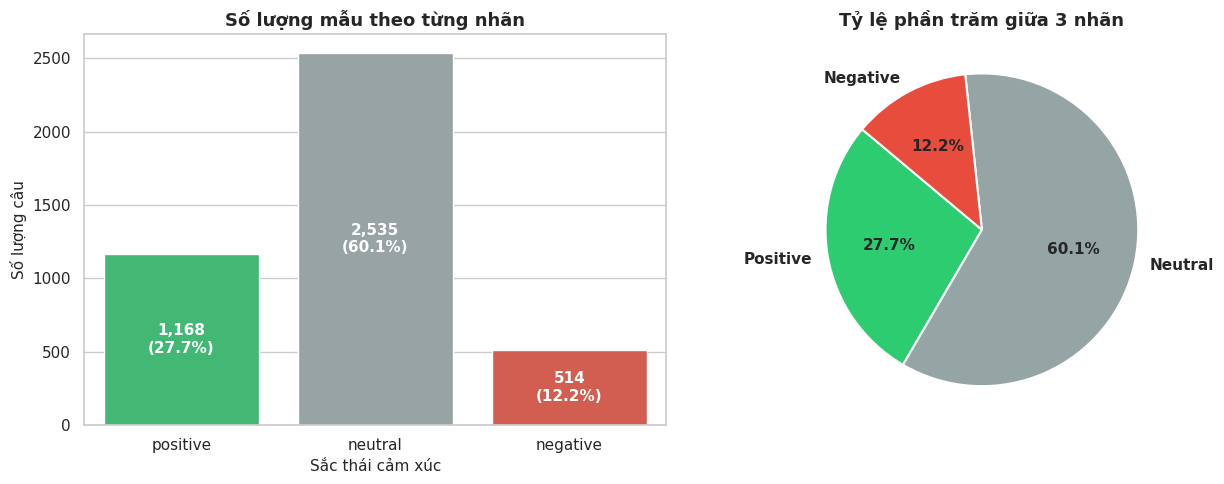

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập giao diện
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Thứ tự và bảng màu đồng nhất cho 3 nhãn
order = ['positive', 'neutral', 'negative']
palette = {'positive': '#2ecc71', 'neutral': '#95a5a6', 'negative': '#e74c3c'}

# 1. BIỂU ĐỒ CỘT (Count Plot)
sns.countplot(
    data=df_benchmark,
    x='sentiment',
    order=order,
    hue='sentiment',
    palette=palette,
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Số lượng mẫu theo từng nhãn', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sắc thái cảm xúc', fontsize=11)
axes[0].set_ylabel('Số lượng câu', fontsize=11)

# Ghi chú thích số lượng và tỷ lệ % ngay trên đầu/thân mỗi cột
total = len(df_benchmark)
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        pct = (height / total) * 100
        axes[0].annotate(
            f'{int(height):,}\n({pct:.1f}%)',
            (p.get_x() + p.get_width() / 2., height / 2),
            ha='center', va='center',
            color='white', fontweight='bold', fontsize=11
        )

# 2. BIỂU ĐỒ TRÒN (Pie Chart)
counts = df_benchmark['sentiment'].value_counts().reindex(order)
pie_colors = [palette[label] for label in order]

axes[1].pie(
    counts,
    labels=[l.capitalize() for l in order],
    autopct='%1.1f%%',
    startangle=140,
    colors=pie_colors,
    textprops={'fontsize': 11, 'fontweight': 'bold'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
axes[1].set_title('Tỷ lệ phần trăm giữa 3 nhãn', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

In [18]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm

# 1. Khởi tạo Dataset & DataLoader
class PhraseBankDataset(Dataset):
    def __init__(self, texts):
        self.texts = texts
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        return self.texts[idx]

test_loader = DataLoader(
    PhraseBankDataset(df_benchmark['sentence'].tolist()), 
    batch_size=64, 
    shuffle=False
)

# 2. Tải FinBERT
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_name = "ProsusAI/finbert"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
model.eval()

id2label = model.config.id2label
predictions = []

# 3. Chạy suy luận theo batch
with torch.no_grad():
    for batch in tqdm(test_loader, desc="Đang đánh giá benchmark"):
        inputs = tokenizer(
            list(batch), 
            padding=True, 
            truncation=True, 
            max_length=128, 
            return_tensors="pt"
        ).to(device)
        
        outputs = model(**inputs)
        preds = torch.argmax(outputs.logits, dim=-1)
        predictions.extend([id2label[p.item()].lower() for p in preds])

df_benchmark['pred_sentiment'] = predictions

# 4. Đánh giá hiệu năng chi tiết
target_names = ['positive', 'neutral', 'negative']
print("\n=== KẾT QUẢ ĐÁNH GIÁ (CLASSIFICATION REPORT) ===")
print(classification_report(
    df_benchmark['sentiment'], 
    df_benchmark['pred_sentiment'], 
    labels=target_names, 
    digits=4
))

print("=== CONFUSION MATRIX ===")
print(confusion_matrix(
    df_benchmark['sentiment'], 
    df_benchmark['pred_sentiment'], 
    labels=target_names
))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Đang đánh giá benchmark:   0%|          | 0/66 [00:00<?, ?it/s]


=== KẾT QUẢ ĐÁNH GIÁ (CLASSIFICATION REPORT) ===
              precision    recall  f1-score   support

    positive     0.8605    0.9401    0.8985      1168
     neutral     0.9768    0.8959    0.9346      2535
    negative     0.8166    0.9786    0.8903       514

    accuracy                         0.9182      4217
   macro avg     0.8846    0.9382    0.9078      4217
weighted avg     0.9250    0.9182    0.9192      4217

=== CONFUSION MATRIX ===
[[1098   49   21]
 [ 172 2271   92]
 [   6    5  503]]


In [19]:
import os
import glob
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# ==========================================
# 1. TẢI MÔ HÌNH FINBERT LÊN THIẾT BỊ
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_name = "ProsusAI/finbert"

print(f"Đang tải {model_name} lên {device}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
model.eval()

id2label = {idx: label.lower() for idx, label in model.config.id2label.items()}
target_names = ['positive', 'neutral', 'negative']

# ==========================================
# 2. ĐỊNH NGHĨA DATASET & HÀM SUY LUẬN
# ==========================================
class PhraseBankDataset(Dataset):
    def __init__(self, texts):
        self.texts = texts
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        return self.texts[idx]

def evaluate_subset(texts, labels, batch_size=64):
    loader = DataLoader(PhraseBankDataset(texts), batch_size=batch_size, shuffle=False)
    preds = []
    
    with torch.no_grad():
        for batch in loader:
            inputs = tokenizer(
                list(batch),
                padding=True,
                truncation=True,
                max_length=128,
                return_tensors="pt"
            ).to(device)
            
            outputs = model(**inputs)
            batch_preds = torch.argmax(outputs.logits, dim=-1)
            preds.extend([id2label[p.item()] for p in batch_preds])
            
    acc = accuracy_score(labels, preds)
    macro_f1 = f1_score(labels, preds, labels=target_names, average='macro')
    weighted_f1 = f1_score(labels, preds, labels=target_names, average='weighted')
    cm = confusion_matrix(labels, preds, labels=target_names)
    report = classification_report(labels, preds, labels=target_names, digits=4)
    
    return {
        'accuracy': acc,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'cm': cm,
        'report': report,
        'preds': preds
    }

# ==========================================
# 3. NẠP 4 FILE, TÁCH 20% TEST SET VÀ ĐÁNH GIÁ
# ==========================================
dataset_names = [
    'Sentences_AllAgree.txt',
    'Sentences_75Agree.txt',
    'Sentences_66Agree.txt',
    'Sentences_50Agree.txt'
]

# Thư mục chứa dữ liệu Kaggle
base_dir = "/kaggle/input/datasets/qkhilithi3122411100/financialphasedbank-v1-0"

benchmark_results = {}

for fname in dataset_names:
    file_path = os.path.join(base_dir, fname)
    if not os.path.exists(file_path):
        matches = glob.glob(f"/kaggle/input/**/{fname}", recursive=True)
        if matches:
            file_path = matches[0]
        else:
            print(f"Bỏ qua (không tìm thấy): {fname}")
            continue

    df_temp = pd.read_csv(file_path, sep='@', names=['sentence', 'sentiment'], encoding='ISO-8859-1')
    df_temp['sentence'] = df_temp['sentence'].astype(str).str.strip()
    df_temp['sentiment'] = df_temp['sentiment'].astype(str).str.strip().str.lower()
    
    # Trích xuất ngẫu nhiên 20% tổng số câu độc lập làm tập test (stratify để giữ nguyên tỷ lệ nhãn)
    _, test_df = train_test_split(
        df_temp, 
        test_size=0.20, 
        random_state=42, 
        stratify=df_temp['sentiment']
    )
    
    clean_name = fname.replace("Sentences_", "").replace(".txt", "")
    print(f"\n--- Đang kiểm tra tập {clean_name} (20% Test size: {len(test_df):,} mẫu) ---")
    
    res = evaluate_subset(test_df['sentence'].tolist(), test_df['sentiment'].tolist())
    benchmark_results[clean_name] = res
    print(res['report'])

# ==========================================

Đang tải ProsusAI/finbert lên cuda...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


--- Đang kiểm tra tập AllAgree (20% Test size: 453 mẫu) ---
              precision    recall  f1-score   support

    positive     0.9113    0.9912    0.9496       114
     neutral     1.0000    0.9604    0.9798       278
    negative     0.9516    0.9672    0.9593        61

    accuracy                         0.9691       453
   macro avg     0.9543    0.9730    0.9629       453
weighted avg     0.9712    0.9691    0.9695       453


--- Đang kiểm tra tập 75Agree (20% Test size: 691 mẫu) ---
              precision    recall  f1-score   support

    positive     0.9005    0.9663    0.9322       178
     neutral     0.9951    0.9464    0.9701       429
    negative     0.8913    0.9762    0.9318        84

    accuracy                         0.9551       691
   macro avg     0.9290    0.9630    0.9447       691
weighted avg     0.9581    0.9551    0.9557       691


--- Đang kiểm tra tập 66Agree (20% Test size: 844 mẫu) ---
              precision    recall  f1-score   support

  

Đang tải ProsusAI/finbert lên cuda...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Đang kiểm tra AllAgree (453 mẫu test)...
Đang kiểm tra 75Agree (691 mẫu test)...
Đang kiểm tra 66Agree (844 mẫu test)...
Đang kiểm tra 50Agree (970 mẫu test)...

BẢNG KẾT QUẢ ĐÁNH GIÁ FINBERT TRÊN FINANCIAL PHRASEBANK (20% TEST SET)


,Sample_Count,Loss,Accuracy,Macro-F1
AllAgree,453,0.1277,96.91%,0.9629
75Agree,691,0.1777,95.51%,0.9447
66Agree,844,0.2582,92.06%,0.9096
50Agree,970,0.3451,87.22%,0.8633


/tmp/ipykernel_50/4027861533.py:153: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.index, y=results_df['Loss'], palette='Reds_r', ax=axes[0])
/tmp/ipykernel_50/4027861533.py:163: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.index, y=results_df['Accuracy'], palette='Blues', ax=axes[1])
/tmp/ipykernel_50/4027861533.py:174: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.index, y=results_df['Macro-F1'], palette='Greens', ax=axes[2])


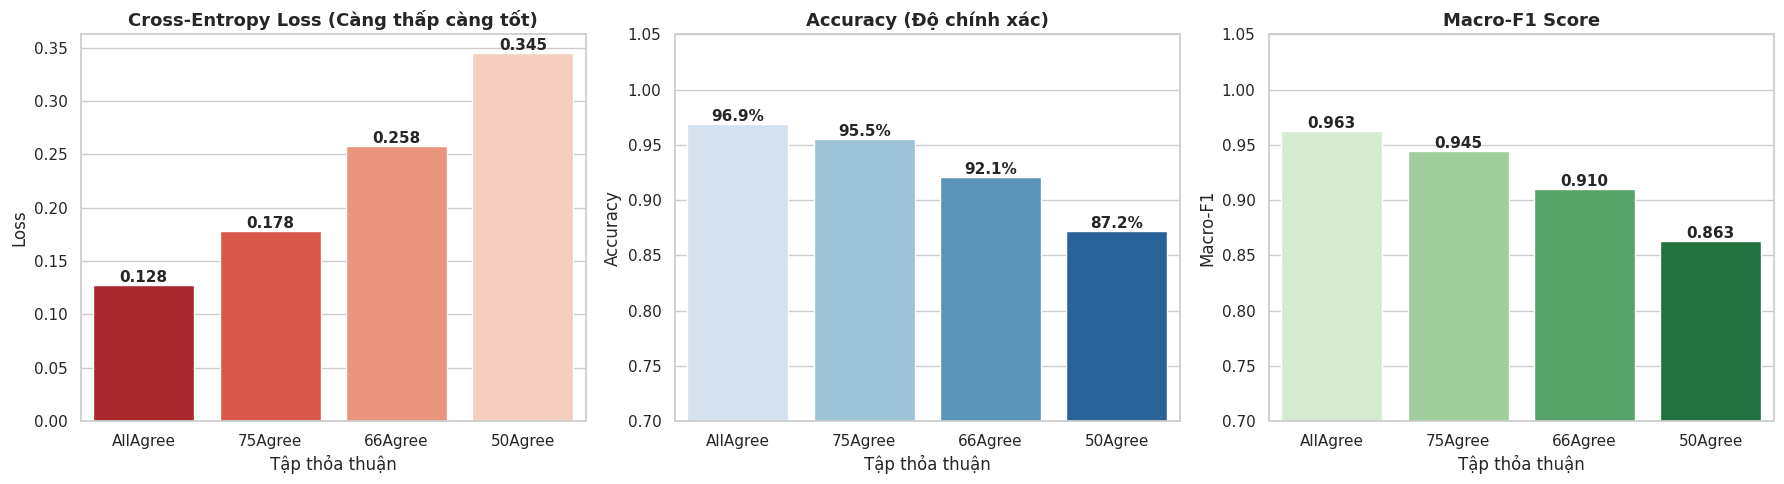

In [20]:
import os
import glob
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# ==========================================
# 1. TẢI MÔ HÌNH FINBERT LÊN THIẾT BỊ
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_name = "ProsusAI/finbert"

print(f"Đang tải {model_name} lên {device}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
model.eval()

# Mapping nhãn chuẩn
id2label = {idx: label.lower() for idx, label in model.config.id2label.items()}
label2id = {v: k for k, v in id2label.items()}
target_names = ['positive', 'neutral', 'negative']

# ==========================================
# 2. ĐỊNH NGHĨA DATASET & HÀM ĐÁNH GIÁ (LOSS, ACCURACY, MACRO-F1)
# ==========================================
class PhraseBankDataset(Dataset):
    def __init__(self, texts):
        self.texts = texts
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        return self.texts[idx]

def evaluate_subset(texts, labels, batch_size=64):
    loader = DataLoader(PhraseBankDataset(texts), batch_size=batch_size, shuffle=False)
    criterion = nn.CrossEntropyLoss(reduction='sum')
    
    all_logits = []
    preds = []
    total_loss = 0.0
    
    # Chuyển đổi nhãn chuỗi sang tensor ID
    true_labels_idx = torch.tensor([label2id[l] for l in labels], dtype=torch.long)
    
    with torch.no_grad():
        for i, batch in enumerate(loader):
            inputs = tokenizer(
                list(batch),
                padding=True,
                truncation=True,
                max_length=128,
                return_tensors="pt"
            ).to(device)
            
            outputs = model(**inputs)
            logits = outputs.logits
            
            # Tính loss theo từng batch
            batch_labels = true_labels_idx[i * batch_size : (i + 1) * batch_size].to(device)
            batch_loss = criterion(logits, batch_labels)
            total_loss += batch_loss.item()
            
            batch_preds = torch.argmax(logits, dim=-1)
            preds.extend([id2label[p.item()] for p in batch_preds])
            
    # Các độ đo chuẩn theo bài báo
    avg_loss = total_loss / len(texts)
    acc = accuracy_score(labels, preds)
    macro_f1 = f1_score(labels, preds, labels=target_names, average='macro')
    
    return {
        'Loss': avg_loss,
        'Accuracy': acc,
        'Macro-F1': macro_f1,
        'Sample_Count': len(texts)
    }

# ==========================================
# 3. NẠP DỮ LIỆU VÀ CHẠY KIỂM TRA TRÊN 4 TẬP
# ==========================================
dataset_names = [
    'Sentences_AllAgree.txt',
    'Sentences_75Agree.txt',
    'Sentences_66Agree.txt',
    'Sentences_50Agree.txt'
]

base_dir = "/kaggle/input/datasets/qkhilithi3122411100/financialphasedbank-v1-0"
benchmark_results = {}

for fname in dataset_names:
    file_path = os.path.join(base_dir, fname)
    if not os.path.exists(file_path):
        matches = glob.glob(f"/kaggle/input/**/{fname}", recursive=True)
        if matches:
            file_path = matches[0]
        else:
            print(f"Bỏ qua (không tìm thấy): {fname}")
            continue

    df_temp = pd.read_csv(file_path, sep='@', names=['sentence', 'sentiment'], encoding='ISO-8859-1')
    df_temp['sentence'] = df_temp['sentence'].astype(str).str.strip()
    df_temp['sentiment'] = df_temp['sentiment'].astype(str).str.strip().str.lower()
    
    # Trích xuất ngẫu nhiên 20% test set độc lập
    _, test_df = train_test_split(
        df_temp, 
        test_size=0.20, 
        random_state=42, 
        stratify=df_temp['sentiment']
    )
    
    clean_name = fname.replace("Sentences_", "").replace(".txt", "")
    print(f"Đang kiểm tra {clean_name} ({len(test_df):,} mẫu test)...")
    
    res = evaluate_subset(test_df['sentence'].tolist(), test_df['sentiment'].tolist())
    benchmark_results[clean_name] = res

# ==========================================
# 4. TẠO BẢNG THỐNG KÊ CHUẨN PAPER
# ==========================================
results_df = pd.DataFrame.from_dict(benchmark_results, orient='index')
results_df = results_df[['Sample_Count', 'Loss', 'Accuracy', 'Macro-F1']]

print("\n" + "="*60)
print("BẢNG KẾT QUẢ ĐÁNH GIÁ FINBERT TRÊN FINANCIAL PHRASEBANK (20% TEST SET)")
print("="*60)
display(results_df.style.format({
    'Sample_Count': '{:,}',
    'Loss': '{:.4f}',
    'Accuracy': '{:.2%}',
    'Macro-F1': '{:.4f}'
}).background_gradient(subset=['Accuracy', 'Macro-F1'], cmap='Greens')
  .background_gradient(subset=['Loss'], cmap='Reds_r'))

# ==========================================
# 5. TRỰC QUAN HÓA BIỂU ĐỒ SO SÁNH
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

dataset_order = list(benchmark_results.keys())

# Biểu đồ 1: Cross-Entropy Loss (Càng thấp càng tốt)
sns.barplot(x=results_df.index, y=results_df['Loss'], palette='Reds_r', ax=axes[0])
axes[0].set_title('Cross-Entropy Loss (Càng thấp càng tốt)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Loss')
axes[0].set_xlabel('Tập thỏa thuận')
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, fontweight='bold')

# Biểu đồ 2: Accuracy
sns.barplot(x=results_df.index, y=results_df['Accuracy'], palette='Blues', ax=axes[1])
axes[1].set_title('Accuracy (Độ chính xác)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0.7, 1.05)
axes[1].set_xlabel('Tập thỏa thuận')
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1%}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, fontweight='bold')

# Biểu đồ 3: Macro-F1 Score
sns.barplot(x=results_df.index, y=results_df['Macro-F1'], palette='Greens', ax=axes[2])
axes[2].set_title('Macro-F1 Score', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Macro-F1')
axes[2].set_ylim(0.7, 1.05)
axes[2].set_xlabel('Tập thỏa thuận')
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.3f}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()